# **A. Regime change challenge**

In [ ]:
!pip install yfinance pandas numpy matplotlib statsmodels arch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 985.3/985.3 kB 26.4 MB/s eta 0:00:00


# **Demonstration**

[*********************100%***********************]  1 of 1 completed


=== GARCH(1,1) Summary ===
                     Constant Mean - GARCH Model Results                      
Dep. Variable:                 Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:                3826.90
Distribution:                  Normal   AIC:                          -7645.81
Method:            Maximum Likelihood   BIC:                          -7625.26
                                        No. Observations:                 1258
Date:                Mon, Jun 30 2025   Df Residuals:                     1257
Time:                        08:01:46   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu         1.3504e-03  1.155e-0

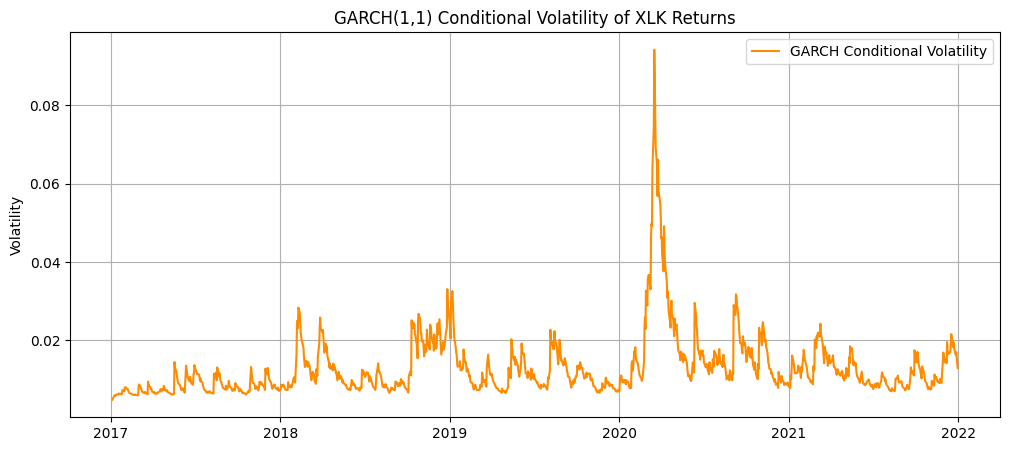

=== Markov Switching Model (2 Regimes) Summary ===
                        Markov Switching Model Results                        
Dep. Variable:                 Return   No. Observations:                 1258
Model:               MarkovRegression   Log Likelihood                3782.032
Date:                Mon, 30 Jun 2025   AIC                          -7552.064
Time:                        08:01:48   BIC                          -7521.240
Sample:                             0   HQIC                         -7540.480
                               - 1258                                         
Covariance Type:               approx                                         
                             Regime 0 parameters                              
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0019      0.000      6.610      0.000       0.001       0.002
s

In [ ]:
# Import required libraries
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from arch import arch_model
from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression
import warnings
warnings.filterwarnings("ignore")

# Download XLK ETF data
data = yf.download("XLK", start="2017-01-01", end="2022-01-01", auto_adjust=False)['Adj Close']
data['Return'] = np.log(data).diff()
returns = data['Return'].dropna()

# Estimate GARCH(1,1) model on full return series
garch_mod = arch_model(returns, vol='GARCH', p=1, q=1)
garch_res = garch_mod.fit(disp='off')

print("=== GARCH(1,1) Summary ===")
print(garch_res.summary())

# 4. Plot conditional volatility from GARCH
plt.figure(figsize=(12,5))
plt.plot(garch_res.conditional_volatility, label="GARCH Conditional Volatility", color='darkorange')
plt.title("GARCH(1,1) Conditional Volatility of XLK Returns")
plt.ylabel("Volatility")
plt.legend()
plt.grid(True)
plt.show()

# Estimate Markov Switching Model with 2 regimes (mean and variance switching)
msm_model = MarkovRegression(returns, k_regimes=2, trend='c', switching_variance=True)
msm_result = msm_model.fit()

print("=== Markov Switching Model (2 Regimes) Summary ===")
print(msm_result.summary())

Date
2017-01-04         NaN
2017-01-05         NaN
2017-01-06         NaN
2017-01-09         NaN
2017-01-10         NaN
                ...   
2021-12-27    0.012151
2021-12-28    0.012142
2021-12-29    0.012136
2021-12-30    0.012145
2021-12-31    0.012152
Name: Return, Length: 1258, dtype: float64


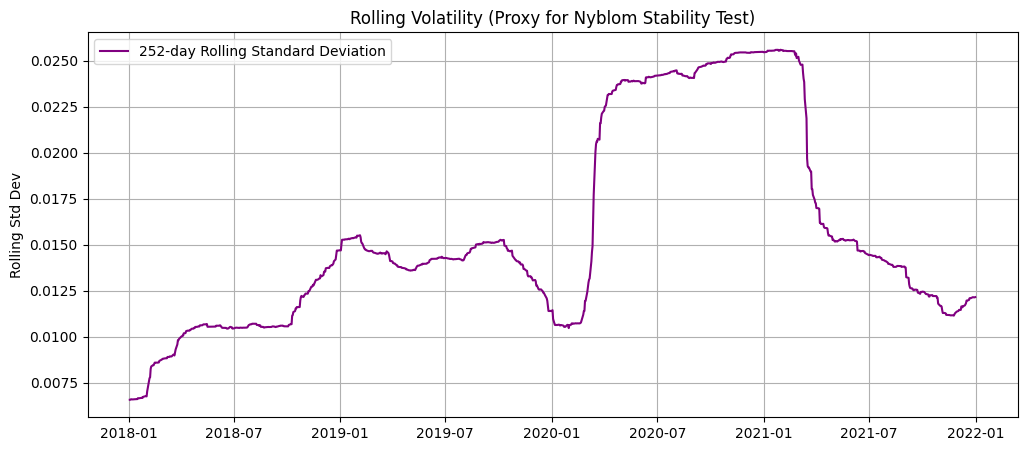

In [ ]:
# Check for volatility instability: Rolling Std Dev as Nyblom-like proxy
rolling_std = returns.rolling(window=252).std()

print(rolling_std)

plt.figure(figsize=(12,5))
plt.plot(rolling_std, label="252-day Rolling Standard Deviation", color='purple')
plt.title("Rolling Volatility (Proxy for Nyblom Stability Test)")
plt.ylabel("Rolling Std Dev")
plt.legend()
plt.grid(True)
plt.show()


=== Regime Classification ===
→ Regime 0 is classified as Bull Market (low volatility)
→ Regime 1 is classified as Bear Market (high volatility)


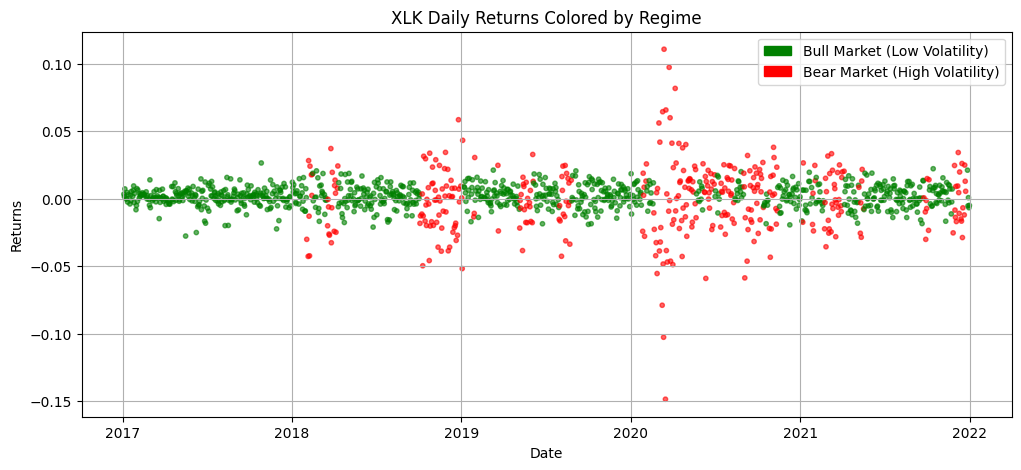

In [ ]:
import matplotlib.patches as mpatches

# Get smoothed probabilities
probs = msm_result.smoothed_marginal_probabilities

# === Determine which regime is Bull (lower volatility) and Bear (higher volatility) ===
regime_vols = msm_result.params[['sigma2[0]', 'sigma2[1]']]
bull_regime = np.argmin(regime_vols)  # lower variance
bear_regime = 1 - bull_regime

print("\n=== Regime Classification ===")
print(f"→ Regime {bull_regime} is classified as Bull Market (low volatility)")
print(f"→ Regime {bear_regime} is classified as Bear Market (high volatility)")

# === Plot Returns with Regime Colors ===
colors = returns.copy()
colors[:] = 'gray'  # default color

colors[probs[bull_regime] > 0.5] = 'green'
colors[probs[bear_regime] > 0.5] = 'red'

plt.figure(figsize=(12,5))
plt.scatter(returns.index, returns, c=colors, s=10, alpha=0.6)
plt.title("XLK Daily Returns Colored by Regime")
plt.ylabel("Returns")
plt.xlabel("Date")
plt.grid(True)

# === Add Legend ===
bull_patch = mpatches.Patch(color='green', label='Bull Market (Low Volatility)')
bear_patch = mpatches.Patch(color='red', label='Bear Market (High Volatility)')

plt.legend(handles=[bull_patch, bear_patch], loc='upper right')

plt.show()

# **Diagram**

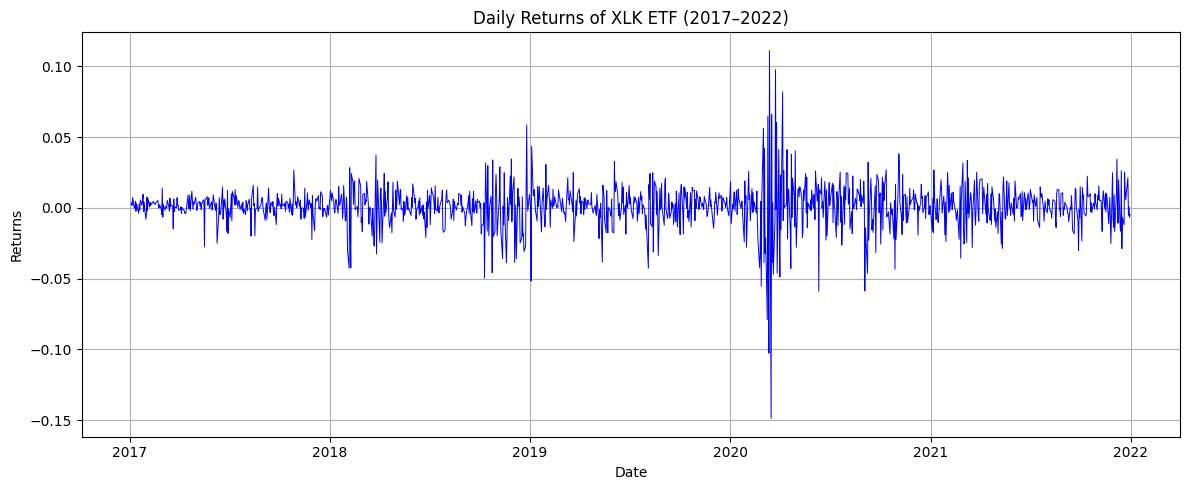

In [ ]:
# XLK returns from 2017 to 2022
plt.figure(figsize=(12, 5))
plt.plot(returns.index, returns, color='blue', linewidth=0.7)
plt.title("Daily Returns of XLK ETF (2017–2022)")
plt.xlabel("Date")
plt.ylabel("Returns")
plt.grid(True)
plt.tight_layout()
plt.show()

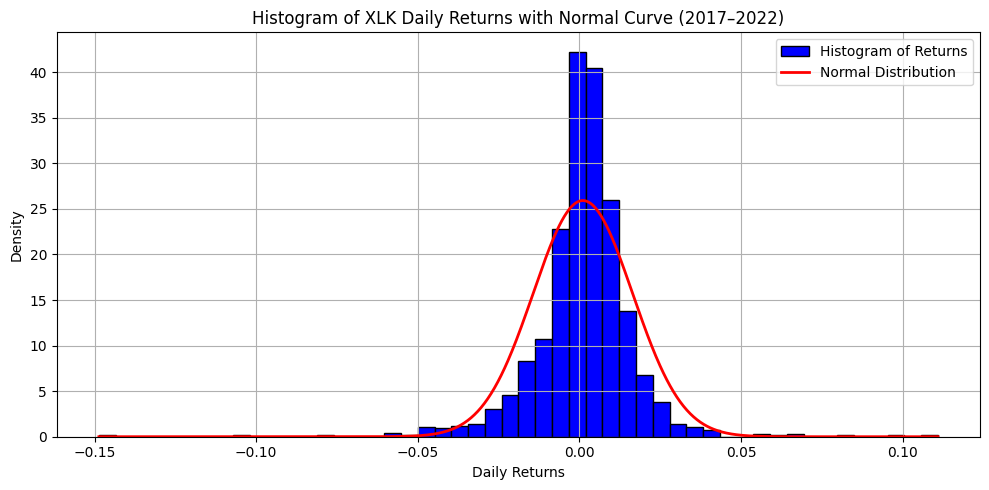

In [ ]:
# Histogram of XLK returns
from scipy.stats import norm

# Estimate mean and std for normal distribution
mu, sigma = returns.mean(), returns.std()

# Create histogram
plt.figure(figsize=(10, 5))
count, bins, ignored = plt.hist(returns, bins=50, density=True, color='blue', edgecolor='black', label='Histogram of Returns')

# Overlay normal distribution curve
x = np.linspace(returns.min(), returns.max(), 1000)
plt.plot(x, norm.pdf(x, mu, sigma), color='red', linewidth=2, label='Normal Distribution')

# Add title and labels
plt.title("Histogram of XLK Daily Returns with Normal Curve (2017–2022)")
plt.xlabel("Daily Returns")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

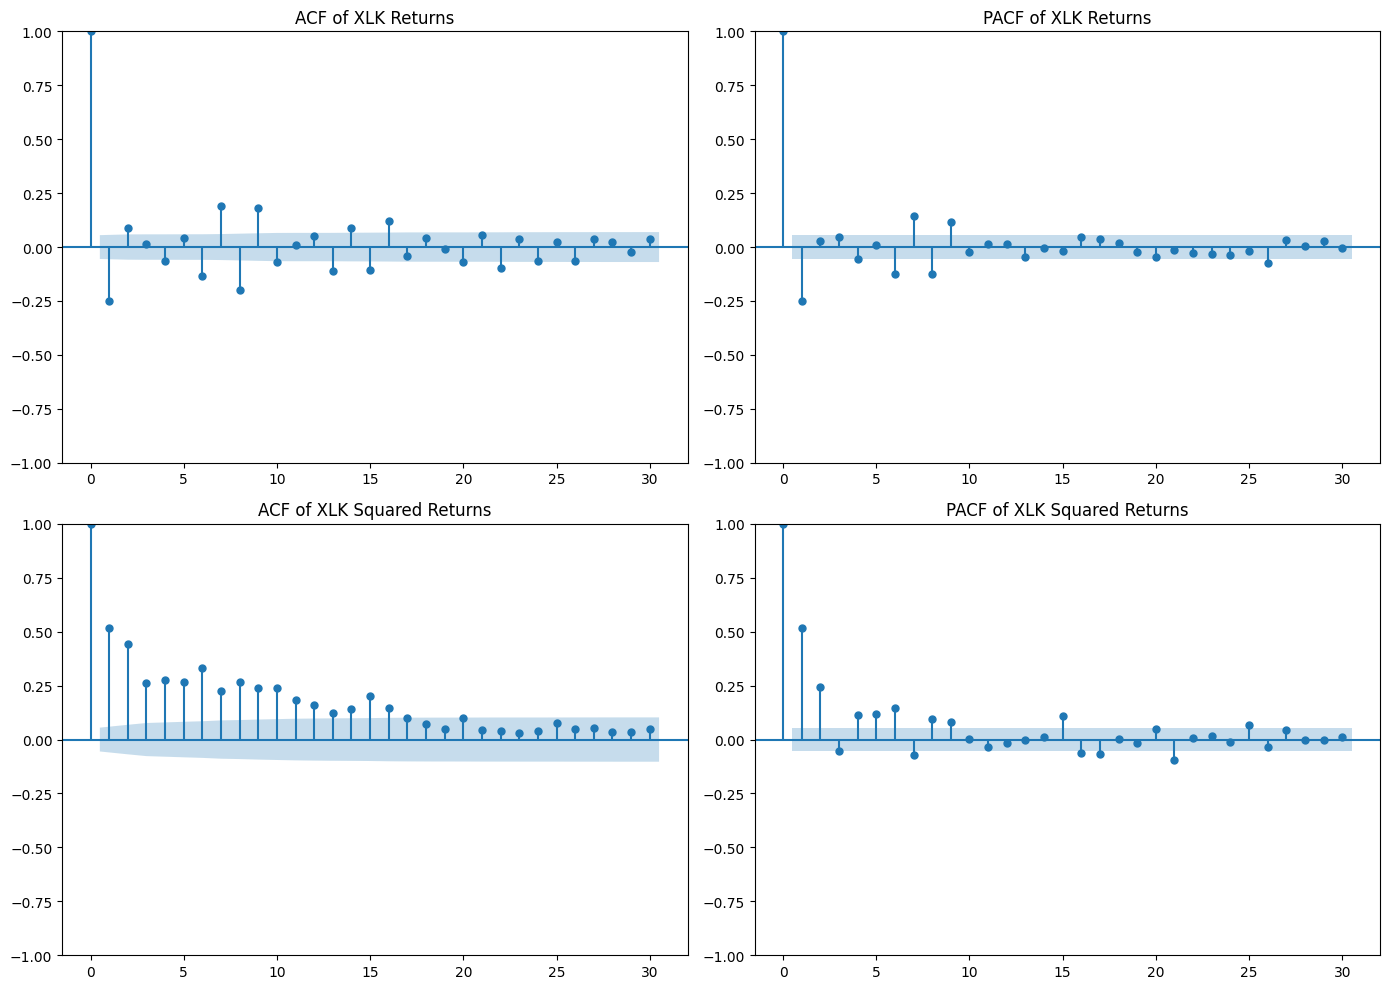

In [ ]:
# ACF and PACF
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

squared_returns = returns ** 2

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ACF and PACF for returns
plot_acf(returns, ax=axes[0, 0], lags=30, title='ACF of XLK Returns')
plot_pacf(returns, ax=axes[0, 1], lags=30, title='PACF of XLK Returns', method='ywm')

# ACF and PACF for squared returns
plot_acf(squared_returns, ax=axes[1, 0], lags=30, title='ACF of XLK Squared Returns')
plot_pacf(squared_returns, ax=axes[1, 1], lags=30, title='PACF of XLK Squared Returns', method='ywm')

plt.tight_layout()
plt.show()

# **Diagnosis**

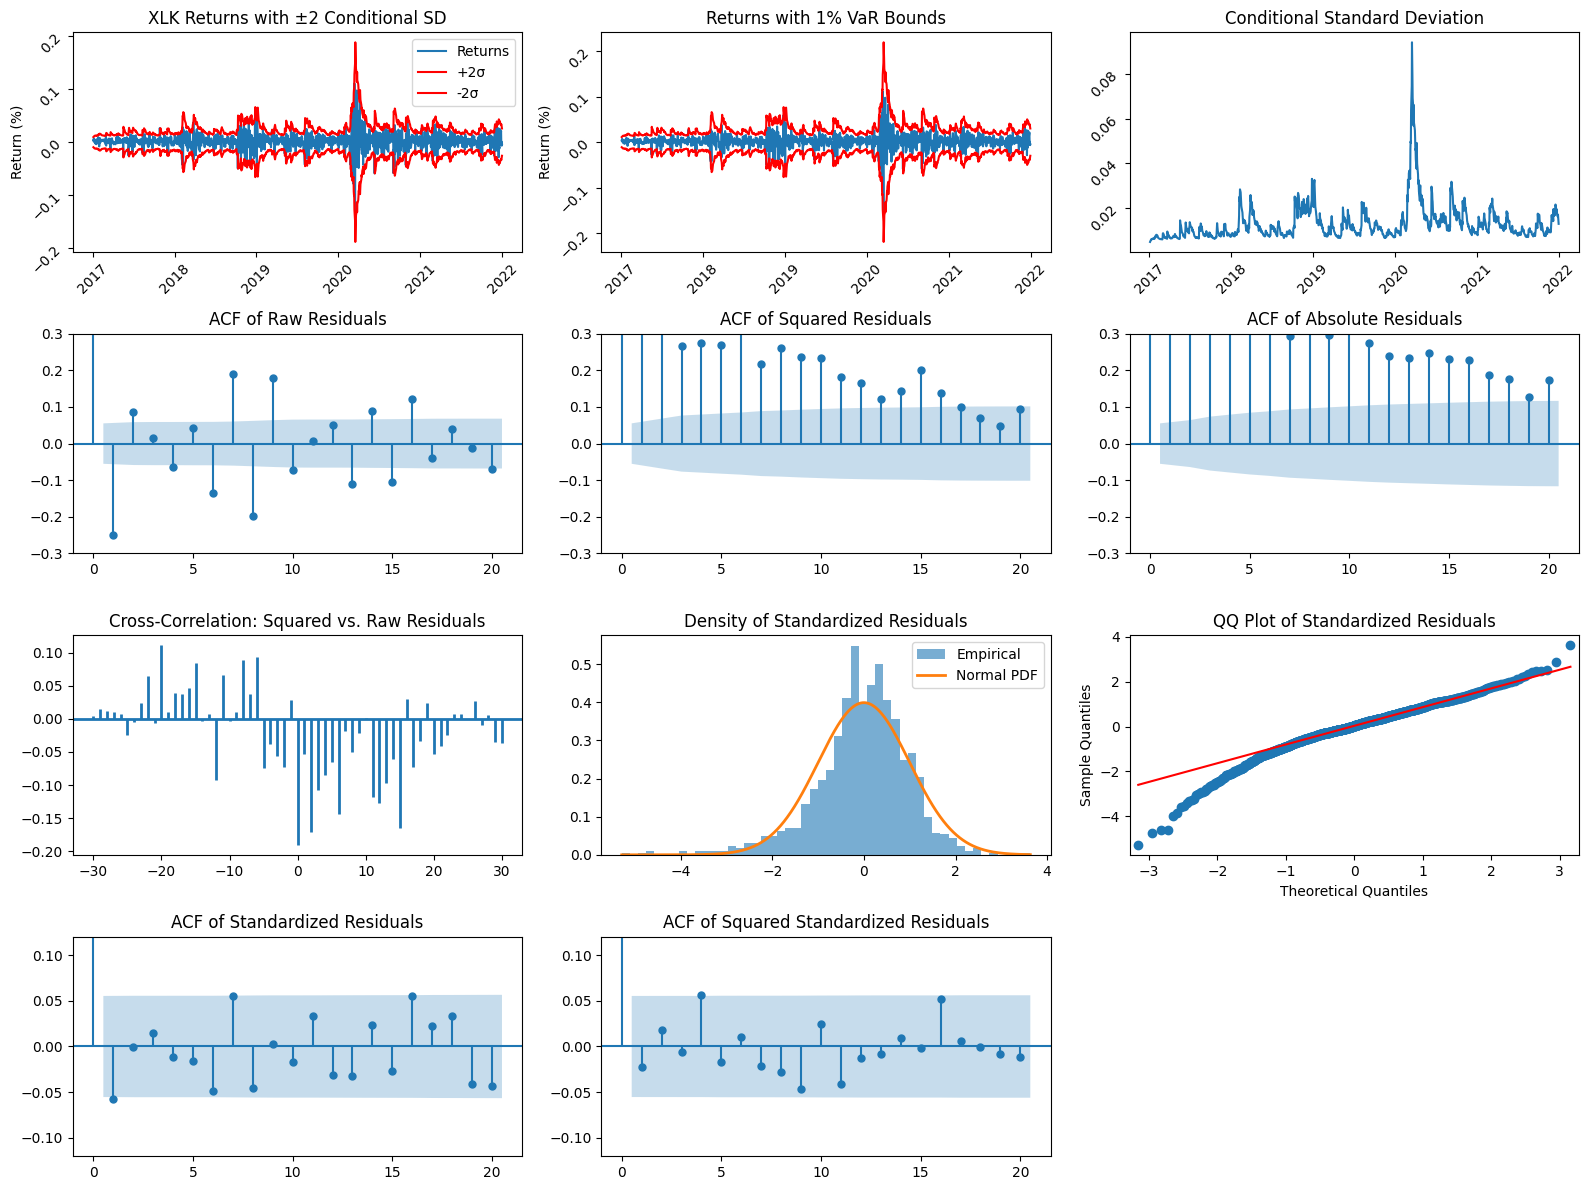

In [ ]:
# Diagnostic plots: Model Diagnostic Plots for the GARCH(1,1) Model with Normal White Noise
import scipy.stats as stats
import statsmodels.api as sm

fig, ax = plt.subplots(4, 3, figsize=(16, 12))

# Row 1 Col 1: Returns with ±2 conditional SD
ax[0, 0].plot(returns.index, returns, label="Returns")
ax[0, 0].plot(returns.index, 2.0 * garch_res.conditional_volatility, c="r", label="+2σ")
ax[0, 0].plot(returns.index, -2.0 * garch_res.conditional_volatility, c="r", label="-2σ")
ax[0, 0].tick_params(labelrotation=45)
ax[0, 0].set_title("XLK Returns with ±2 Conditional SD")
ax[0, 0].set_ylabel("Return (%)")
ax[0, 0].legend()

# Row 1 Col 2: Returns with VaR 1%
VaR_1 = stats.norm.ppf(0.99)
ax[0, 1].plot(returns.index, returns)
ax[0, 1].plot(returns.index, VaR_1 * garch_res.conditional_volatility, c="r")
ax[0, 1].plot(returns.index, -VaR_1 * garch_res.conditional_volatility, c="r")
ax[0, 1].tick_params(labelrotation=45)
ax[0, 1].set_title("Returns with 1% VaR Bounds")
ax[0, 1].set_ylabel("Return (%)")

# Row 1 Col 3: Conditional SD
ax[0, 2].plot(returns.index, garch_res.conditional_volatility)
ax[0, 2].set_title("Conditional Standard Deviation")
ax[0, 2].tick_params(labelrotation=45)

# Row 2: ACF plots of raw, squared, and abs residuals
sm.graphics.tsa.plot_acf(garch_res.resid, lags=20, ax=ax[1, 0])
ax[1, 0].set_title("ACF of Raw Residuals")
ax[1, 0].set_ylim([-0.3, 0.3])

sm.graphics.tsa.plot_acf(garch_res.resid**2, lags=20, ax=ax[1, 1])
ax[1, 1].set_title("ACF of Squared Residuals")
ax[1, 1].set_ylim([-0.3, 0.3])

sm.graphics.tsa.plot_acf(np.abs(garch_res.resid), lags=20, ax=ax[1, 2])
ax[1, 2].set_title("ACF of Absolute Residuals")
ax[1, 2].set_ylim([-0.3, 0.3])

# Row 3 Col 1: Cross-correlation between squared residuals and raw residuals
ax[2, 0].xcorr(garch_res.resid**2, garch_res.resid, usevlines=True, maxlags=30, normed=True, lw=2)
ax[2, 0].set_title("Cross-Correlation: Squared vs. Raw Residuals")

# Row 3 Col 2: Empirical vs. Normal density of standardized residuals
std_resid = garch_res.std_resid
x_vals = np.linspace(std_resid.min(), std_resid.max(), len(std_resid))
ax[2, 1].hist(std_resid, bins=50, density=True, alpha=0.6, label='Empirical')
ax[2, 1].plot(x_vals, stats.norm.pdf(x_vals), lw=2, label='Normal PDF')
ax[2, 1].set_title("Density of Standardized Residuals")
ax[2, 1].legend()

# Row 3 Col 3: QQ plot
sm.qqplot(std_resid, line="q", ax=ax[2, 2])
ax[2, 2].set_title("QQ Plot of Standardized Residuals")

# Row 4: ACF of standardized residuals and their squares
sm.graphics.tsa.plot_acf(std_resid, lags=20, ax=ax[3, 0])
ax[3, 0].set_title("ACF of Standardized Residuals")
ax[3, 0].set_ylim([-0.12, 0.12])

sm.graphics.tsa.plot_acf(std_resid**2, lags=20, ax=ax[3, 1])
ax[3, 1].set_title("ACF of Squared Standardized Residuals")
ax[3, 1].set_ylim([-0.12, 0.12])

# Turn off empty subplot
ax[3, 2].axis("off")

fig.tight_layout()
plt.show()

# **Direction**

In [ ]:
# Outlier filtering

from scipy.stats.mstats import winsorize

# Winsorize returns at 1% and 99% percentiles
returns_winsorized = pd.Series(winsorize(returns, limits=[0.01, 0.01]), index=returns.index)

from arch import arch_model

# Fit GARCH(1,1) on winsorized returns
garch_model_clean = arch_model(returns_winsorized, vol='GARCH', p=1, q=1)
garch_res_clean = garch_model_clean.fit(disp='off')

# Summary
print(garch_res_clean.summary())

from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression

# Fit MSM with 2 regimes using winsorized data
msm_model_clean = MarkovRegression(returns_winsorized, k_regimes=2, trend='c', switching_variance=True)
msm_res_clean = msm_model_clean.fit()

# Summary
print(msm_res_clean.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                   None   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:                3851.12
Distribution:                  Normal   AIC:                          -7694.23
Method:            Maximum Likelihood   BIC:                          -7673.68
                                        No. Observations:                 1258
Date:                Mon, Jun 30 2025   Df Residuals:                     1257
Time:                        08:01:57   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu         1.3163e-03  4.533e-06    290.406      0.000 [1.

In [ ]:
# Epand GARCH and MSM
from arch import arch_model
from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression

# EGARCH(1,1) allows asymmetric effects
egarch_model = arch_model(returns, vol='EGARCH', p=1, o=1, q=1)
egarch_res = egarch_model.fit(disp='off')
print(egarch_res.summary())

# Estimate a 3-regime Markov Switching model
msm_3 = MarkovRegression(returns, k_regimes=3, trend='c', switching_variance=True)
msm_3_res = msm_3.fit()
print(msm_3_res.summary())

                     Constant Mean - EGARCH Model Results                     
Dep. Variable:                 Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                     EGARCH   Log-Likelihood:                3830.81
Distribution:                  Normal   AIC:                          -7651.63
Method:            Maximum Likelihood   BIC:                          -7625.94
                                        No. Observations:                 1258
Date:                Mon, Jun 30 2025   Df Residuals:                     1257
Time:                        08:02:00   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu         7.3396e-04  2.509e-04      2.925  3.442e-03 [2.

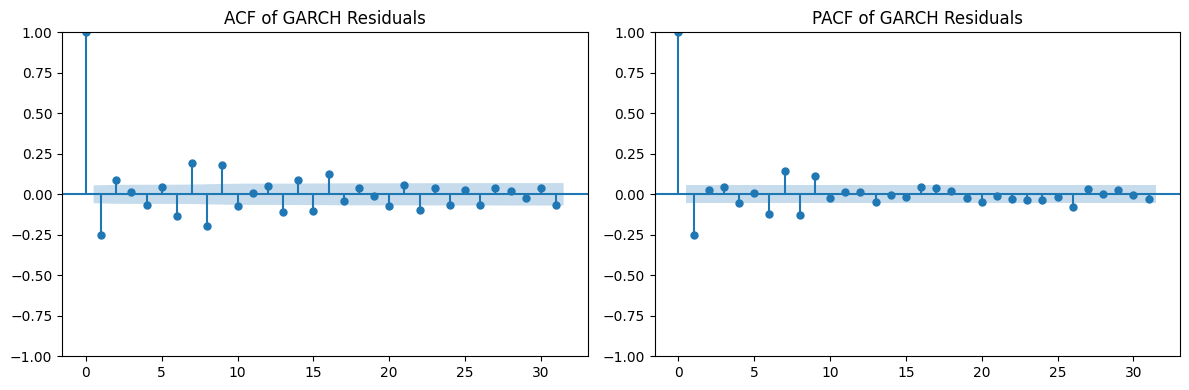

In [ ]:
# residual check
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

residuals = garch_res.resid.dropna()

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plot_acf(residuals, ax=plt.gca(), title="ACF of GARCH Residuals")
plt.subplot(1,2,2)
plot_pacf(residuals, ax=plt.gca(), title="PACF of GARCH Residuals")
plt.tight_layout()
plt.show()

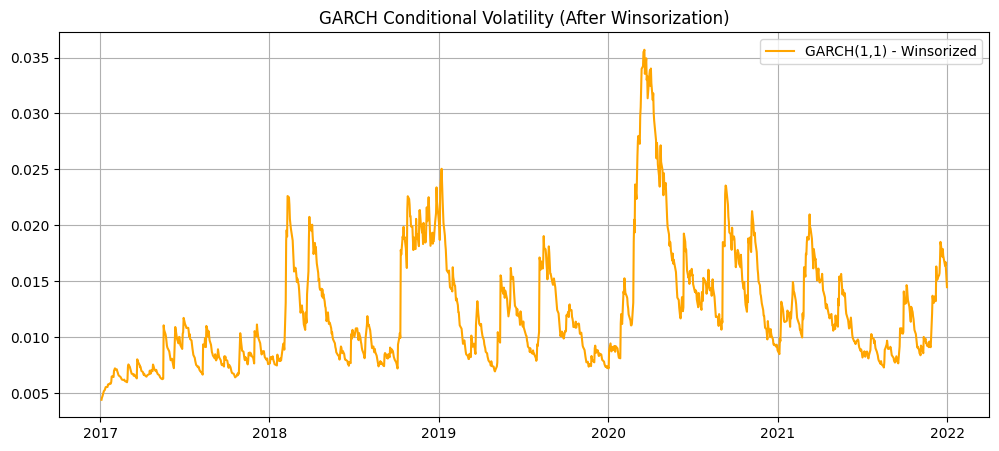

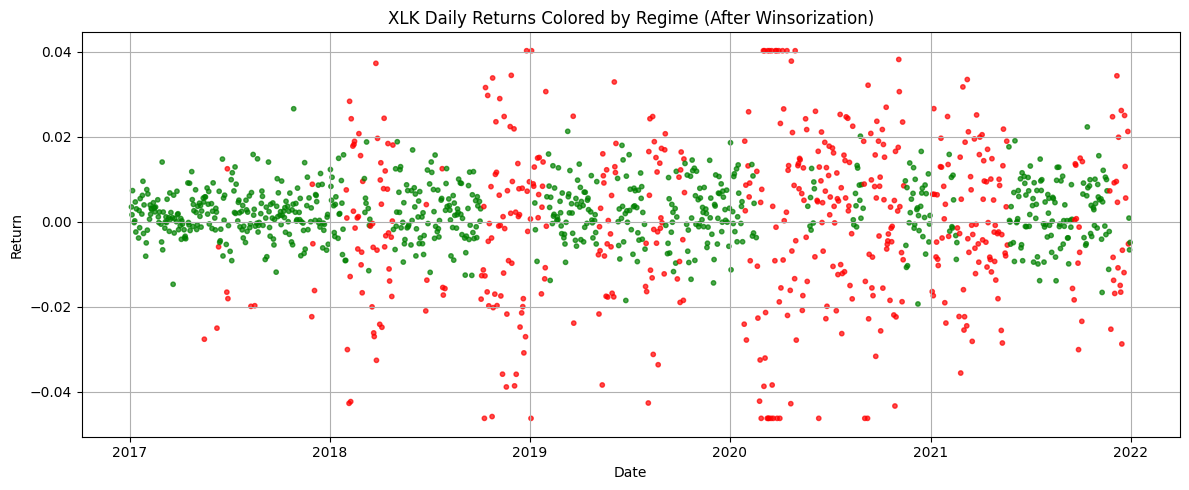

In [ ]:
# Replot data with removed outliner
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(garch_res_clean.conditional_volatility, label="GARCH(1,1) - Winsorized", color='orange')
plt.title("GARCH Conditional Volatility (After Winsorization)")
plt.legend()
plt.grid(True)
plt.show()

# Use the cleaned (winsorized) returns and MSM results
returns_clean = returns_winsorized
probs_clean = msm_res_clean.smoothed_marginal_probabilities

# Identify which regime is bull (low volatility) and bear (high volatility)
regime_vols = msm_res_clean.params[['sigma2[0]', 'sigma2[1]']]
bull_regime = np.argmin(regime_vols)  # regime with lower variance
bear_regime = 1 - bull_regime

# Assign colors based on regime probabilities
colors = ['gray'] * len(returns_clean)

for i in range(len(returns_clean)):
    if probs_clean[bull_regime].iloc[i] > 0.5:
        colors[i] = 'green'
    elif probs_clean[bear_regime].iloc[i] > 0.5:
        colors[i] = 'red'

# Create the scatter plot
plt.figure(figsize=(12, 5))
plt.scatter(returns_clean.index, returns_clean.values, c=colors, s=10, alpha=0.7)
plt.title("XLK Daily Returns Colored by Regime (After Winsorization)")
plt.ylabel("Return")
plt.xlabel("Date")
plt.grid(True)
plt.tight_layout()
plt.show()

# **Deployment**

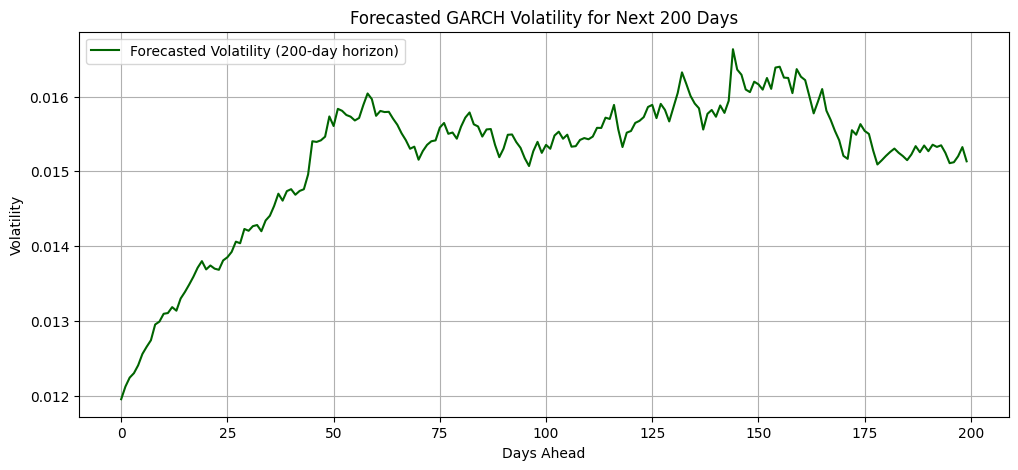

In [ ]:
# Set forecast horizon
horizon = 200

# Forecast conditional volatility for the next 200 days
garch_forecast = garch_res.forecast(horizon=horizon, method='simulation')
forecast_vol = np.sqrt(garch_forecast.variance.values[-1])  # extract forecasted volatilities

# Plot forecasted volatility over the 200-day horizon
plt.figure(figsize=(12, 5))
plt.plot(forecast_vol, label="Forecasted Volatility (200-day horizon)", color='darkgreen')
plt.title("Forecasted GARCH Volatility for Next 200 Days")
plt.ylabel("Volatility")
plt.xlabel("Days Ahead")
plt.grid(True)
plt.legend()
plt.show()


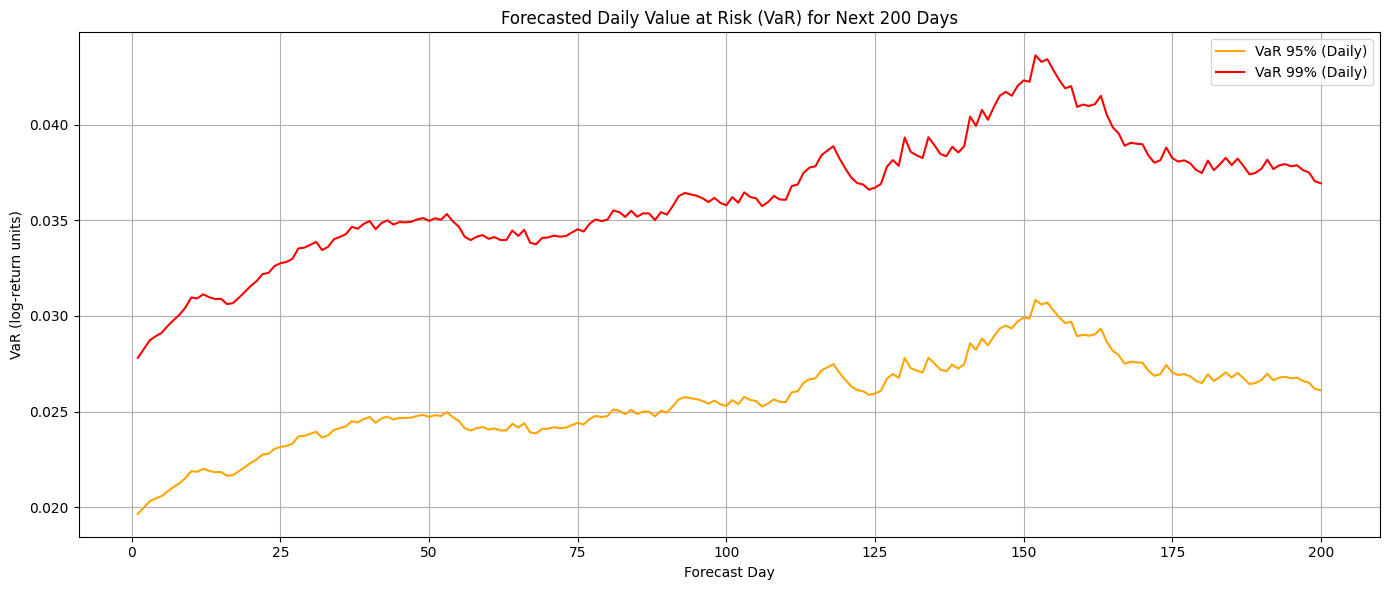

In [ ]:
# Forecast volatility for 200 days ahead
horizon = 200
garch_forecast = garch_res.forecast(horizon=horizon, method='simulation')
forecast_vol = np.sqrt(garch_forecast.variance.values[-1])  # shape: (200,)

# Z-scores for 95% and 99% confidence levels
z_95 = norm.ppf(0.05)  # ≈ -1.645
z_99 = norm.ppf(0.01)  # ≈ -2.326

# Calculate daily VaR for each of the 200 forecast days
VaR_95_series = -z_95 * forecast_vol
VaR_99_series = -z_99 * forecast_vol

# Create day index for plotting
days = np.arange(1, horizon + 1)

# Plot 200-day daily VaR
plt.figure(figsize=(14, 6))
plt.plot(days, VaR_95_series, label="VaR 95% (Daily)", color='orange')
plt.plot(days, VaR_99_series, label="VaR 99% (Daily)", color='red')
plt.title("Forecasted Daily Value at Risk (VaR) for Next 200 Days")
plt.xlabel("Forecast Day")
plt.ylabel("VaR (log-return units)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# **B. Multicollinearity issue**

Dataset structure:
      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD    TAX  \
0  0.00632  18.0   2.31   0.0  0.538  6.575  65.2  4.0900  1.0  296.0   
1  0.02731   0.0   7.07   0.0  0.469  6.421  78.9  4.9671  2.0  242.0   
2  0.02729   0.0   7.07   0.0  0.469  7.185  61.1  4.9671  2.0  242.0   
3  0.03237   0.0   2.18   0.0  0.458  6.998  45.8  6.0622  3.0  222.0   
4  0.06905   0.0   2.18   0.0  0.458  7.147  54.2  6.0622  3.0  222.0   

   PTRATIO       B  LSTAT  MEDV  
0     15.3  396.90   4.98  24.0  
1     17.8  396.90   9.14  21.6  
2     17.8  392.83   4.03  34.7  
3     18.7  394.63   2.94  33.4  
4     18.7  396.90   5.33  36.2  


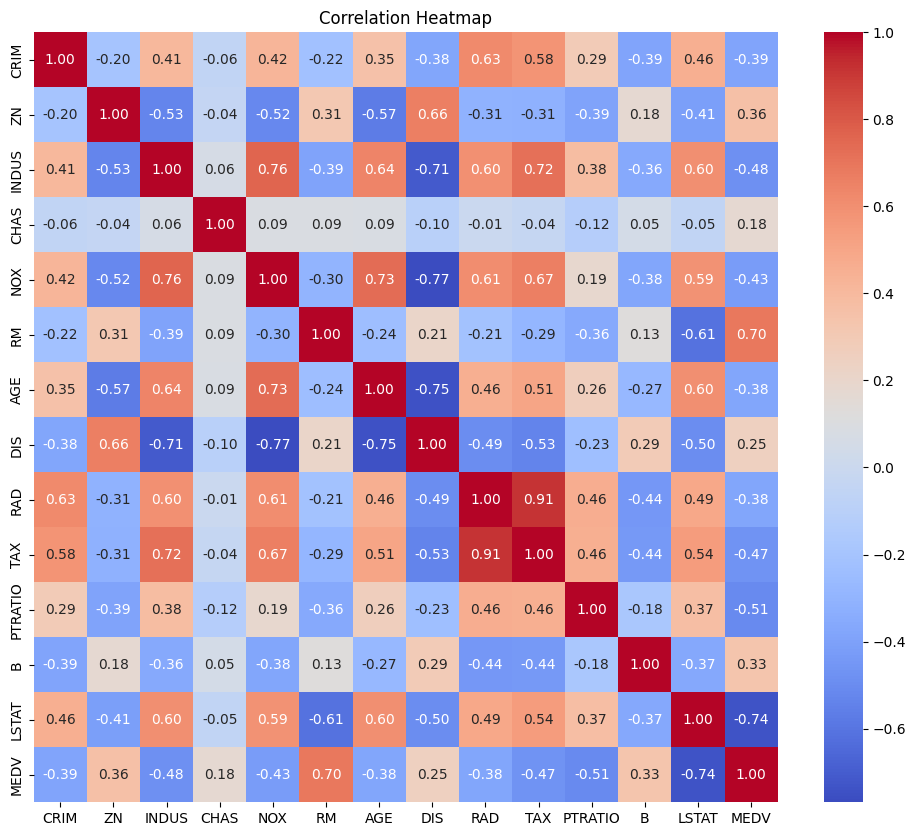


Variance Inflation Factors:
    Feature         VIF
0     const  585.265238
1      CRIM    1.792192
2        ZN    2.298758
3     INDUS    3.991596
4      CHAS    1.073995
5       NOX    4.393720
6        RM    1.933744
7       AGE    3.100826
8       DIS    3.955945
9       RAD    7.484496
10      TAX    9.008554
11  PTRATIO    1.799084
12        B    1.348521
13    LSTAT    2.941491


In [ ]:
# Step 1: Import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.api import OLS, add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Load the boston dataset
data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep="\\s+", skiprows=22, header=None)
data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
target = raw_df.values[1::2, 2]

# Construct the DataFrame
columns = [
    "CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE",
    "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT"
]
df = pd.DataFrame(data, columns=columns)
df["MEDV"] = target

# Step 3: Show the structure
print("Dataset structure:")
print(df.head())

# Step 4: Correlation heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

# Step 5: Calculate VIF for each feature
X = add_constant(df.drop(columns='MEDV'))  # Add intercept
vif_data = pd.DataFrame()
vif_data['Feature'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

print("\nVariance Inflation Factors:")
print(vif_data)

# **C. Non-stationary analysis**

**Title: Modeling Non-Stationarity and Finding an Equilibrium**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss, coint
from statsmodels.tsa.ardl import ardl_select_order
from pandas_datareader import data as pdr
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan

In [2]:
# Load monthly data from 2000 to 2024
start_date = '2000-01-01'
end_date = '2024-12-31'
inflation_raw = pdr.DataReader('CPIAUCSL', 'fred', start_date, end_date)
interest_rate = pdr.DataReader('FEDFUNDS', 'fred', start_date, end_date)

In [3]:
# Process inflation to monthly % change
inflation = inflation_raw.pct_change() * 100

In [4]:
# Combine datasets(concatenate)
data = pd.concat([inflation, interest_rate], axis=1)
data.columns = ['Inflation', 'Interest Rate']
data.dropna(inplace=True)

In [5]:
# ADF and KPSS tests
def adf_test(series, name):
    result = adfuller(series)
    print(f"ADF Test - {name}: p-value = {result[1]:.4f}")
    return result[1]

In [6]:
def kpss_test(series, name):
    result = kpss(series, regression='c', nlags="auto")
    print(f"KPSS Test - {name}: p-value = {result[1]:.4f}")
    return result[1]

In [ ]:
adf_test(data['Inflation'], "Inflation")
adf_test(data['Interest Rate'], "Interest Rate")
kpss_test(data['Inflation'], "Inflation")
kpss_test(data['Interest Rate'], "Interest Rate")

ADF Test - Inflation: p-value = 0.0243
ADF Test - Interest Rate: p-value = 0.0033
KPSS Test - Inflation: p-value = 0.1000
KPSS Test - Interest Rate: p-value = 0.0615


np.float64(0.061519737046854095)

In [7]:
# Differencing for I(1) variable
data['D_Inflation'] = data['Inflation'].diff()
data['D_Interest_Rate'] = data['Interest Rate'].diff()
data.dropna(inplace=True)

In [8]:
# ARDL(1,0)(p,q) selection and fitting
model_selection = ardl_select_order(
    endog=data['Inflation'],
    exog=data[['Interest Rate']],
    maxlag=4, maxorder=4, ic='aic',
    trend='c'
)

model_ardl = model_selection.model.fit()
print(model_ardl.summary())

                              ARDL Model Results                              
Dep. Variable:              Inflation   No. Observations:                  298
Model:                     ARDL(4, 4)   Log Likelihood                  -5.941
Method:               Conditional MLE   S.D. of innovations              0.247
Date:                Mon, 30 Jun 2025   AIC                             33.883
Time:                        14:23:42   BIC                             74.402
Sample:                    07-01-2000   HQIC                            50.109
                         - 12-01-2024                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const                0.0832      0.025      3.355      0.001       0.034       0.132
Inflation.L1         0.5308      0.058      9.106      0.000       0.416       0.645
Inflation.L2        -0.2098 

/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [9]:
# Cointegration test (Engle-Granger)
coint_result = coint(data['Inflation'], data['Interest Rate'])
print(f"Engle-Granger Cointegration p-value: {coint_result[1]:.4f}")

Engle-Granger Cointegration p-value: 0.0660


In [10]:
# Residual and ECM
resid = model_ardl.resid
data['ECM(-1)'] = resid.shift(1)
data.dropna(inplace=True)

In [11]:
# Residual and ECM
# Redo differencing and ECM term calculation to ensure index alignment
data['D_Inflation'] = data['Inflation'].diff()
data['D_Interest_Rate'] = data['Interest Rate'].diff()
resid = model_ardl.resid
data['ECM(-1)'] = resid.shift(1)
data.dropna(inplace=True)


# ECM estimation
X_ecm = sm.add_constant(data[['D_Interest_Rate', 'ECM(-1)']])
y_ecm = data['D_Inflation']
ecm_model = sm.OLS(y_ecm, X_ecm).fit()
print(ecm_model.summary())

                            OLS Regression Results                            
Dep. Variable:            D_Inflation   R-squared:                       0.153
Model:                            OLS   Adj. R-squared:                  0.147
Method:                 Least Squares   F-statistic:                     26.06
Date:                Mon, 30 Jun 2025   Prob (F-statistic):           3.93e-11
Time:                        14:23:47   Log-Likelihood:                -49.885
No. Observations:                 292   AIC:                             105.8
Df Residuals:                     289   BIC:                             116.8
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.0023      0.017     

In [12]:
# Diagnostics
lb_test = acorr_ljungbox(ecm_model.resid, lags=[10], return_df=True)
bp_test = het_breuschpagan(ecm_model.resid, X_ecm)

In [13]:
print(f"Ljung-Box (p-value): {lb_test['lb_pvalue'].iloc[0]:.4f}")
print(f"Breusch-Pagan (p-value): {bp_test[1]:.4f}")

Ljung-Box (p-value): 0.0000
Breusch-Pagan (p-value): 0.6175


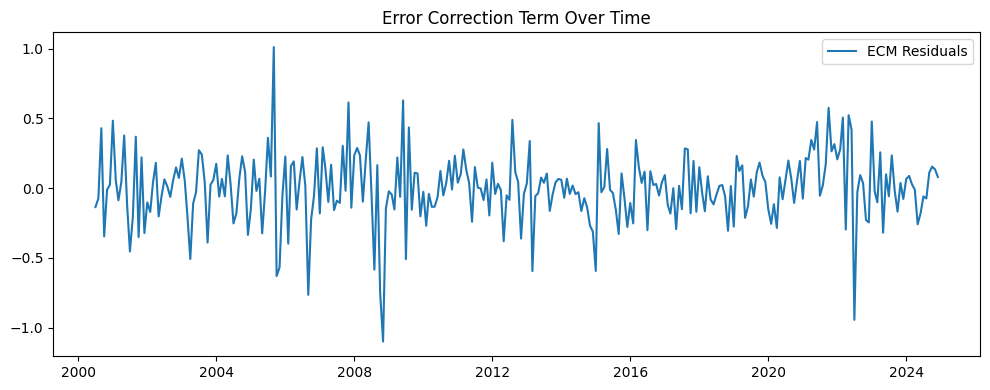

In [14]:
# Plots
plt.figure(figsize=(10, 4))
plt.plot(resid, label="ECM Residuals")
plt.title("Error Correction Term Over Time")
plt.legend()
plt.tight_layout()
plt.show()

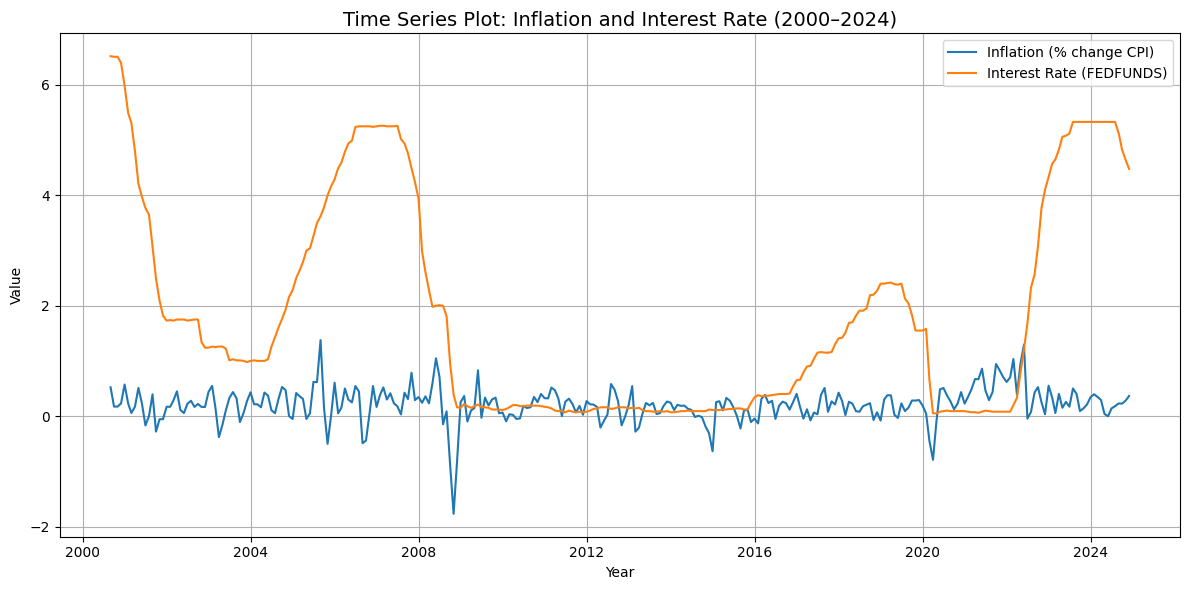

In [15]:
# Plot time series
plt.figure(figsize=(12, 6))
plt.plot(data.index, data['Inflation'], label='Inflation (% change CPI)', linewidth=1.5)
plt.plot(data.index, data['Interest Rate'], label='Interest Rate (FEDFUNDS)', linewidth=1.5)
plt.title("Time Series Plot: Inflation and Interest Rate (2000–2024)", fontsize=14)
plt.xlabel("Year")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

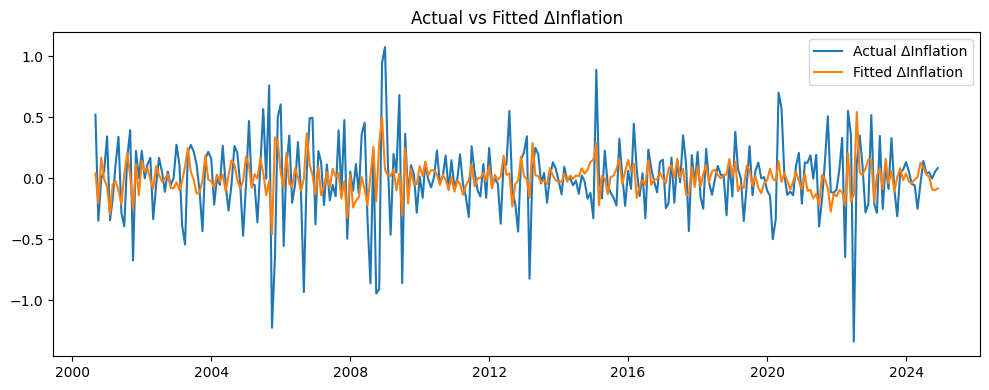

In [16]:
plt.figure(figsize=(10, 4))
plt.plot(data.index, y_ecm, label='Actual ΔInflation')
plt.plot(data.index, ecm_model.fittedvalues, label='Fitted ΔInflation')
plt.title("Actual vs Fitted ΔInflation")
plt.legend()
plt.tight_layout()
plt.show()